# Why Raw Distance Matrices Are Bad Perron-Vector Inputs

This notebook tests the phenomenon behind the lemma from the notes: when the Perron vector is computed from a raw distance matrix, the maximal entry tends to occur at an extreme point of the ordered scale family. That is undesirable for scale selection, because it makes the method prefer boundary scales rather than an intrinsic/interior scale.

The notebook compares two choices:

1. raw distance matrix

$$
D_{ij}=d(x_i,x_j),
$$

2. transformed similarity matrix

$$
S_{ij}=\exp(-\gamma D_{ij}).
$$

The distance matrix rewards being far away from many other scales. The similarity matrix rewards being close to many other scales. This reversal is the main reason the Perron vector of a distance matrix is usually not the right object for selecting a representative bandwidth.
---

**Archive note.** These numerical checks are retained for reference; the boundary-selection claim is intended to be established theoretically in the thesis.


In [1]:
from __future__ import annotations

import os
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".matplotlib-cache"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from kde_tools.bandwidths import bandwidth_grid_linear_in_psi_beta

plt.style.use("seaborn-v0_8-whitegrid")
np.set_printoptions(precision=4, suppress=True)


## Shared helper functions

In [2]:
def perron_vector_symmetric(matrix: np.ndarray) -> tuple[float, np.ndarray]:
    """Largest eigenvalue and sign-normalized Perron vector of a symmetric matrix."""
    matrix = np.asarray(matrix, dtype=float)
    eigenvalues, eigenvectors = np.linalg.eigh((matrix + matrix.T) / 2.0)
    index = int(np.argmax(eigenvalues))
    vector = eigenvectors[:, index]
    if vector.sum() < 0:
        vector = -vector
    if np.any(vector < -1e-10):
        vector = np.abs(vector)
    if vector.sum() > 0:
        vector = vector / vector.sum()
    return float(eigenvalues[index]), vector


def exp_similarity(distance_matrix: np.ndarray, gamma: float = 1.0) -> tuple[np.ndarray, float]:
    gamma_value = float(gamma)
    if not np.isfinite(gamma_value) or gamma_value <= 0.0:
        raise ValueError("gamma must be finite and strictly positive.")
    return np.exp(-gamma_value * distance_matrix), gamma_value


def endpoint_label(index: int, n_points: int) -> str:
    if index == 0:
        return "left boundary"
    if index == n_points - 1:
        return "right boundary"
    return "interior"


def summarize_selection(name: str, grid: np.ndarray, vector: np.ndarray) -> dict[str, object]:
    index = int(np.argmax(vector))
    return {
        "matrix": name,
        "selected_index": index,
        "selected_value": float(grid[index]),
        "location": endpoint_label(index, len(grid)),
        "max_weight": float(vector[index]),
    }


def plot_matrix_and_perron(matrix: np.ndarray, grid: np.ndarray, title: str, ax_matrix, ax_vector):
    _, vector = perron_vector_symmetric(matrix)
    selected_index = int(np.argmax(vector))
    image = ax_matrix.imshow(matrix, origin="lower", aspect="auto", cmap="viridis")
    ax_matrix.set_title(title)
    ax_matrix.set_xlabel("index j")
    ax_matrix.set_ylabel("index i")
    plt.colorbar(image, ax=ax_matrix, fraction=0.046, pad=0.04)

    ax_vector.plot(grid, vector, marker="o", markersize=3, lw=2)
    ax_vector.axvline(grid[selected_index], color="tab:red", ls="--", lw=2)
    ax_vector.set_title(f"Perron vector, selected {endpoint_label(selected_index, len(grid))}")
    ax_vector.set_xlabel("ordered scale value")
    ax_vector.set_ylabel("normalized weight")
    return vector


## Experiment 1: ordered points on an interval

Take points on a line segment,

$$
x_1<\dots<x_N\in[0,1],
$$

and define

$$
D_{ij}=|x_i-x_j|.
$$

The distance-matrix Perron vector should prefer one of the endpoints. This is the simplest finite-dimensional version of the boundary-selection problem.

,matrix,selected_index,selected_value,location,max_weight
0,raw distance D,0,0.0,left boundary,0.034270
1,similarity exp(-gamma D),20,0.5,interior,0.029284


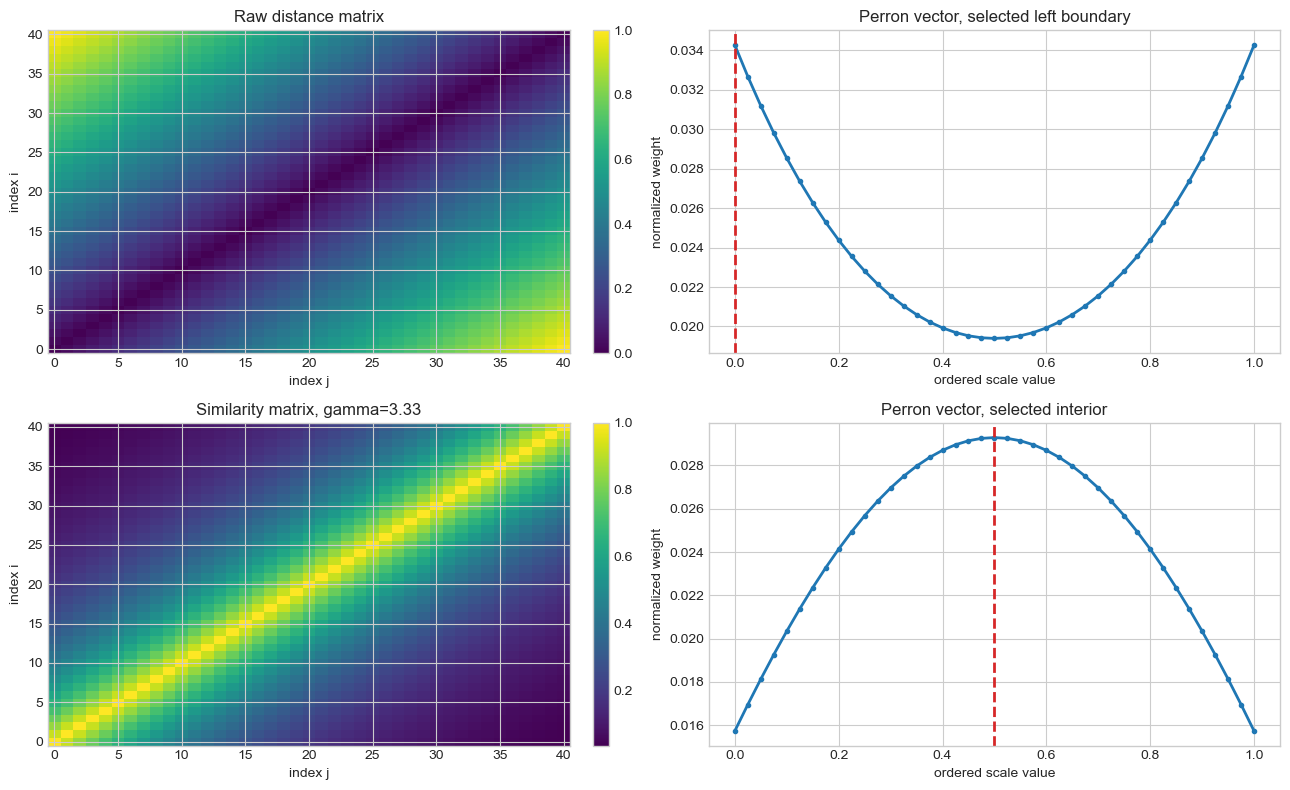

In [3]:
n_grid_interval = 41
interval_grid = np.linspace(0.0, 1.0, n_grid_interval)
interval_distance = np.abs(interval_grid[:, None] - interval_grid[None, :])
interval_similarity, interval_gamma = exp_similarity(interval_distance, gamma=1.0)

_, interval_distance_vector = perron_vector_symmetric(interval_distance)
_, interval_similarity_vector = perron_vector_symmetric(interval_similarity)

summary_interval = pd.DataFrame([
    summarize_selection("raw distance D", interval_grid, interval_distance_vector),
    summarize_selection(r"similarity exp(-gamma D)", interval_grid, interval_similarity_vector),
])

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
plot_matrix_and_perron(interval_distance, interval_grid, "Raw distance matrix", axes[0, 0], axes[0, 1])
plot_matrix_and_perron(interval_similarity, interval_grid, rf"Similarity matrix, gamma={interval_gamma:.3g}", axes[1, 0], axes[1, 1])
fig.tight_layout()

summary_interval


## Experiment 2: power distances

The endpoint effect is not special to the linear distance. We also test

$$
D^{(p)}_{ij}=|x_i-x_j|^p.
$$

For several exponents, the raw distance matrix still selects a boundary point.

,matrix,selected_index,selected_value,location,max_weight
0,|x-y|^0.5,40,1.0,right boundary,0.029480
1,|x-y|^1,0,0.0,left boundary,0.034270
2,|x-y|^1.5,0,0.0,left boundary,0.038967
3,|x-y|^2,40,1.0,right boundary,0.043738


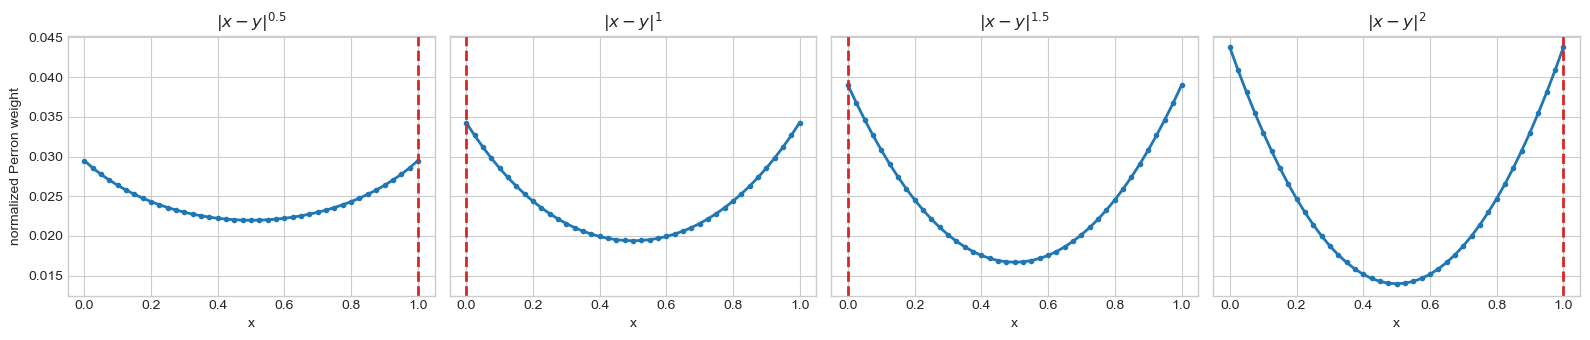

In [4]:
power_results = []
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)

for ax, power in zip(axes, [0.5, 1.0, 1.5, 2.0]):
    D_power = interval_distance ** power
    _, vector_power = perron_vector_symmetric(D_power)
    selected_index = int(np.argmax(vector_power))
    ax.plot(interval_grid, vector_power, marker="o", markersize=3, lw=2)
    ax.axvline(interval_grid[selected_index], color="tab:red", ls="--", lw=2)
    ax.set_title(rf"$|x-y|^{{{power:g}}}$")
    ax.set_xlabel("x")
    power_results.append(summarize_selection(rf"|x-y|^{power:g}", interval_grid, vector_power))

axes[0].set_ylabel("normalized Perron weight")
fig.tight_layout()

pd.DataFrame(power_results)


## Exact Gaussian KDE distance matrices

Now we repeat the test for bandwidths. For one sample from

$$
X_1,\dots,X_n\sim N(0,\sigma^2),
$$

we compute Gaussian KDEs \(\hat f_h\) on a bandwidth grid. The squared \(L^2\) distance is computed exactly by Gaussian convolution:

$$
\langle \hat f_{h_i},\hat f_{h_j}\rangle
=
\frac{1}{n^2}\sum_{k,l=1}^n
\varphi_{\sqrt{h_i^2+h_j^2}}(X_k-X_l).
$$

Then

$$
\|\hat f_{h_i}-\hat f_{h_j}\|_2^2=I_{ii}+I_{jj}-2I_{ij}.
$$

We compare Perron vectors of

- raw squared distance \(D_{ij}=\|\hat f_{h_i}-\hat f_{h_j}\|_2^2\),
- raw distance \(D_{ij}=\|\hat f_{h_i}-\hat f_{h_j}\|_2\),
- similarity \(S_{ij}=\exp(-\gamma\|\hat f_{h_i}-\hat f_{h_j}\|_2^2)\),
- oracle ISE benchmark.

In [5]:
def gaussian_pdf_sd(x: np.ndarray, sd: float) -> np.ndarray:
    return np.exp(-0.5 * (x / sd) ** 2) / (sd * np.sqrt(2.0 * np.pi))


def bandwidth_grid_for_gaussian_experiment(n: int, sigma2: float, n_h: int = 60) -> np.ndarray:
    sigma = np.sqrt(sigma2)
    h_min = sigma * 0.25 * n ** (-0.45)
    h_max = sigma * 3.00 * n ** (-0.08)
    return bandwidth_grid_linear_in_psi_beta(
        h_min=h_min,
        h_max=h_max,
        beta=2.0,
        grid_size=n_h,
    )


def exact_gaussian_kde_l2_gram(samples: np.ndarray, h_grid: np.ndarray) -> np.ndarray:
    samples = np.asarray(samples, dtype=float)
    h_grid = np.asarray(h_grid, dtype=float)
    pairwise_differences = samples[:, None] - samples[None, :]
    n_h = len(h_grid)
    gram = np.empty((n_h, n_h), dtype=float)

    for i, h_i in enumerate(h_grid):
        for j in range(i, n_h):
            h_j = h_grid[j]
            sd = np.sqrt(h_i**2 + h_j**2)
            value = gaussian_pdf_sd(pairwise_differences, sd).mean()
            gram[i, j] = value
            gram[j, i] = value
    return gram


def squared_l2_distance_from_gram(gram: np.ndarray) -> np.ndarray:
    diagonal = np.diag(gram)
    return np.maximum(diagonal[:, None] + diagonal[None, :] - 2.0 * gram, 0.0)


def exact_kde_true_normal_inner(samples: np.ndarray, h_grid: np.ndarray, sigma2: float) -> np.ndarray:
    samples = np.asarray(samples, dtype=float)
    return np.array([
        gaussian_pdf_sd(samples, np.sqrt(h**2 + sigma2)).mean()
        for h in h_grid
    ])


def exact_oracle_ise_values(samples: np.ndarray, h_grid: np.ndarray, sigma2: float, gram: np.ndarray | None = None) -> np.ndarray:
    if gram is None:
        gram = exact_gaussian_kde_l2_gram(samples, h_grid)
    kde_norm_sq = np.diag(gram)
    kde_true_inner = exact_kde_true_normal_inner(samples, h_grid, sigma2=sigma2)
    sigma = np.sqrt(sigma2)
    true_norm_sq = 1.0 / (2.0 * np.sqrt(np.pi) * sigma)
    return kde_norm_sq - 2.0 * kde_true_inner + true_norm_sq


,matrix,selected_index,selected_value,location,max_weight
0,raw squared L2 distance,69,1.963536,right boundary,0.034907
1,raw L2 distance,69,1.963536,right boundary,0.025381
2,similarity exp(-gamma L2^2),31,0.169758,interior,0.020748
3,oracle ISE minimum,41,0.323312,interior,NaN


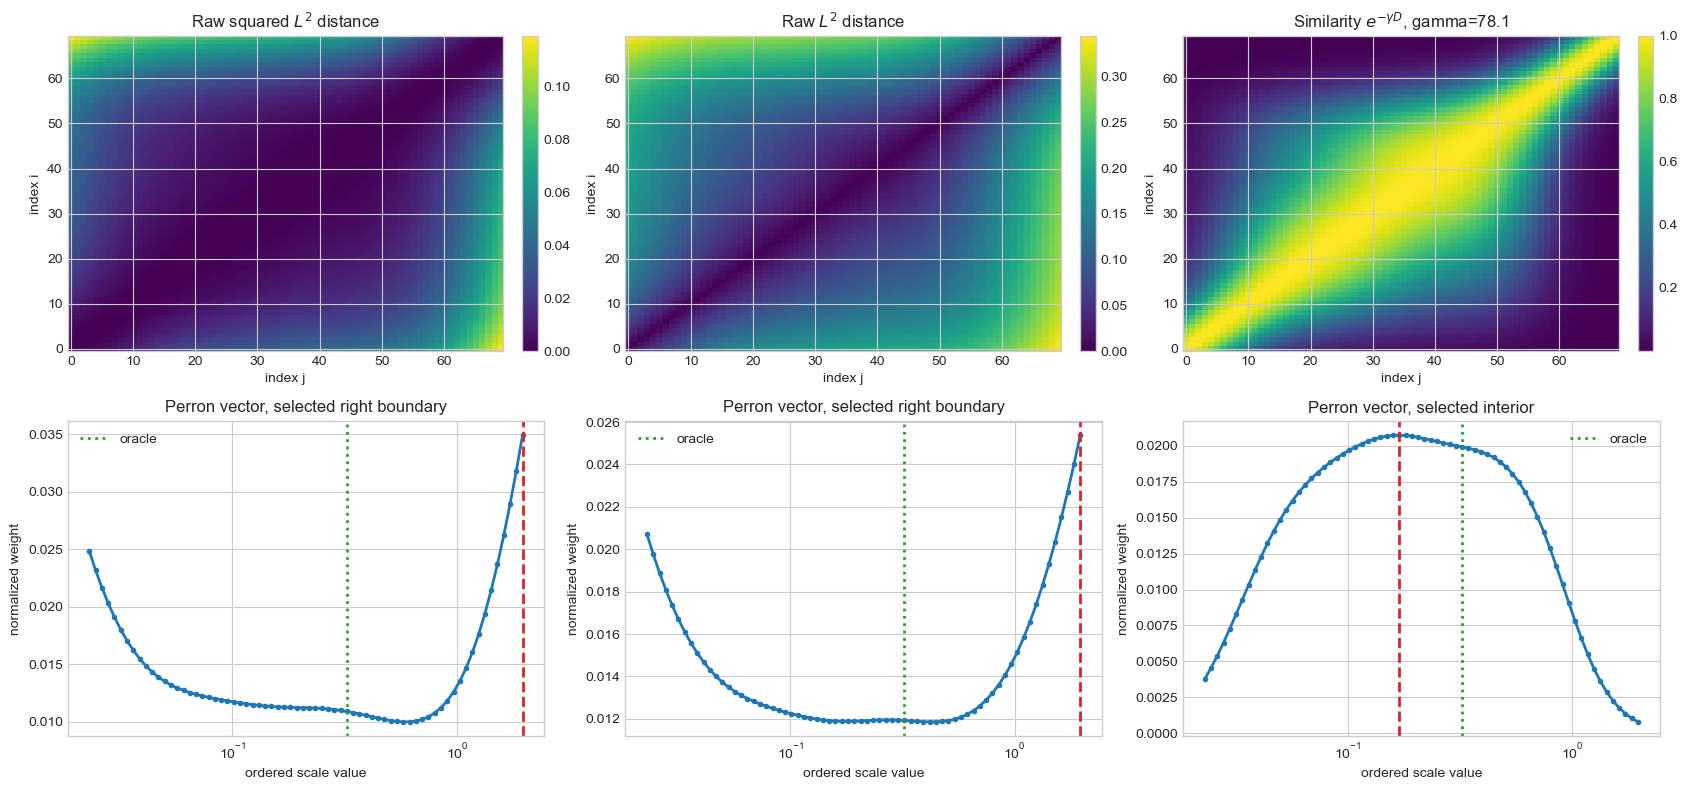

In [6]:
rng = np.random.default_rng(20260715)
n_kde = 200
sigma2_kde = 1.0
n_h_kde = 70

samples = rng.normal(loc=0.0, scale=np.sqrt(sigma2_kde), size=n_kde)
h_grid = bandwidth_grid_for_gaussian_experiment(n=n_kde, sigma2=sigma2_kde, n_h=n_h_kde)
gram = exact_gaussian_kde_l2_gram(samples, h_grid)
D_l2_squared = squared_l2_distance_from_gram(gram)
D_l2 = np.sqrt(D_l2_squared)
S_gamma, gamma_kde = exp_similarity(D_l2_squared, gamma=1.0)
ise_values = exact_oracle_ise_values(samples, h_grid, sigma2=sigma2_kde, gram=gram)
oracle_index = int(np.argmin(ise_values))

_, v_D_squared = perron_vector_symmetric(D_l2_squared)
_, v_D = perron_vector_symmetric(D_l2)
_, v_S = perron_vector_symmetric(S_gamma)

kde_summary = pd.DataFrame([
    summarize_selection(r"raw squared L2 distance", h_grid, v_D_squared),
    summarize_selection(r"raw L2 distance", h_grid, v_D),
    summarize_selection(r"similarity exp(-gamma L2^2)", h_grid, v_S),
    {
        "matrix": "oracle ISE minimum",
        "selected_index": oracle_index,
        "selected_value": float(h_grid[oracle_index]),
        "location": endpoint_label(oracle_index, len(h_grid)),
        "max_weight": np.nan,
    },
])

fig, axes = plt.subplots(2, 3, figsize=(17, 8))
plot_matrix_and_perron(D_l2_squared, h_grid, r"Raw squared $L^2$ distance", axes[0, 0], axes[1, 0])
plot_matrix_and_perron(D_l2, h_grid, r"Raw $L^2$ distance", axes[0, 1], axes[1, 1])
plot_matrix_and_perron(S_gamma, h_grid, rf"Similarity $e^{{-\gamma D}}$, gamma={gamma_kde:.3g}", axes[0, 2], axes[1, 2])
for ax in axes[1]:
    ax.set_xscale("log")
    ax.axvline(h_grid[oracle_index], color="tab:green", ls=":", lw=2, label="oracle")
    ax.legend()
fig.tight_layout()

kde_summary


## Repeated KDE diagnostic

This block repeats the KDE test. The important output is the boundary-selection rate. A raw distance matrix is considered bad if it frequently selects index 0 or index \(N-1\).

,selector,boundary_rate,median_index,median_h,mean_h
0,oracle ISE,0.0,28.0,0.452481,0.479447
1,raw L2 distance,1.0,44.0,2.075493,1.666689
2,raw squared L2 distance,1.0,44.0,2.075493,1.666689
3,similarity exp(-gamma L2^2),0.0,22.0,0.255582,0.246902


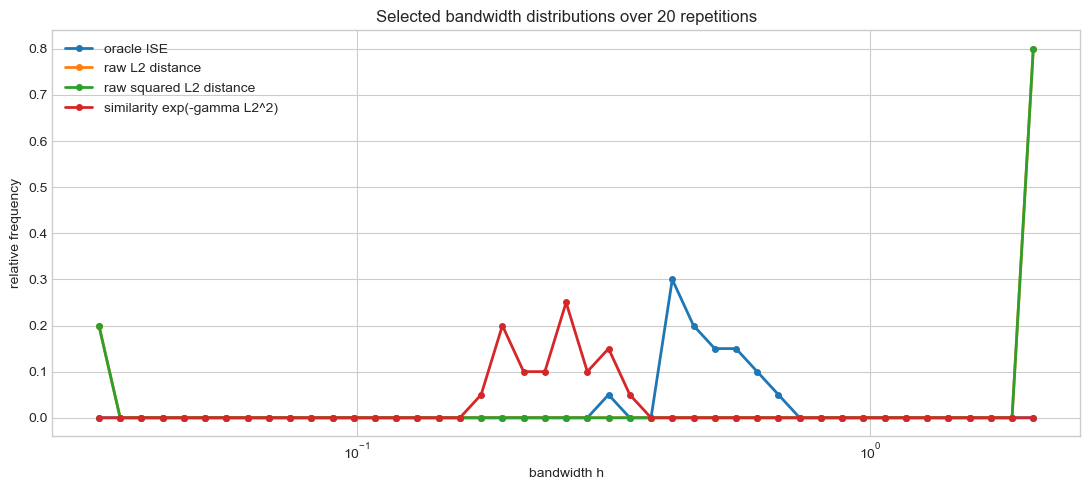

In [7]:
n_repetitions = 20
n_repeated = 100
sigma2_repeated = 1.0
n_h_repeated = 45
base_seed = 910_000

h_grid_repeated = bandwidth_grid_for_gaussian_experiment(n=n_repeated, sigma2=sigma2_repeated, n_h=n_h_repeated)
rows = []

for repetition in range(n_repetitions):
    rng = np.random.default_rng(base_seed + repetition)
    x = rng.normal(loc=0.0, scale=np.sqrt(sigma2_repeated), size=n_repeated)
    gram_current = exact_gaussian_kde_l2_gram(x, h_grid_repeated)
    D2_current = squared_l2_distance_from_gram(gram_current)
    D_current = np.sqrt(D2_current)
    S_current, gamma_current = exp_similarity(D2_current, gamma=1.0)
    ise_current = exact_oracle_ise_values(x, h_grid_repeated, sigma2=sigma2_repeated, gram=gram_current)

    selectors = {
        "raw squared L2 distance": int(np.argmax(perron_vector_symmetric(D2_current)[1])),
        "raw L2 distance": int(np.argmax(perron_vector_symmetric(D_current)[1])),
        "similarity exp(-gamma L2^2)": int(np.argmax(perron_vector_symmetric(S_current)[1])),
        "oracle ISE": int(np.argmin(ise_current)),
    }
    for name, index in selectors.items():
        rows.append({
            "repetition": repetition,
            "selector": name,
            "selected_index": index,
            "selected_h": float(h_grid_repeated[index]),
            "is_boundary": index in {0, len(h_grid_repeated) - 1},
            "gamma": gamma_current,
        })

repeated_results = pd.DataFrame(rows)
summary_repeated = (
    repeated_results.groupby("selector")
    .agg(
        boundary_rate=("is_boundary", "mean"),
        median_index=("selected_index", "median"),
        median_h=("selected_h", "median"),
        mean_h=("selected_h", "mean"),
    )
    .reset_index()
)

fig, ax = plt.subplots(figsize=(11, 5))
for selector, group in repeated_results.groupby("selector"):
    frequencies = np.bincount(group["selected_index"].to_numpy(dtype=int), minlength=len(h_grid_repeated)) / n_repetitions
    ax.plot(h_grid_repeated, frequencies, marker="o", markersize=4, lw=2, label=selector)
ax.set_xscale("log")
ax.set_title(f"Selected bandwidth distributions over {n_repetitions} repetitions")
ax.set_xlabel("bandwidth h")
ax.set_ylabel("relative frequency")
ax.legend()
fig.tight_layout()

summary_repeated


## Interpretation

The raw distance matrix answers the wrong question. A point has a large Perron weight if it is far from many other points. In an ordered family of scales, the points farthest from many other scales are typically the endpoints.

For bandwidth selection, this is exactly the opposite of what we want: we do not want the most extreme bandwidth. We want a representative or structurally central bandwidth. A similarity matrix such as

$$
S_{ij}=\exp(-\gamma D_{ij})
$$

reverses the logic: a point receives a large Perron weight if it is similar to many other points. This is why similarity matrices are more appropriate for Perron-vector based scale selection.